In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
ASSIGNMENT_DIR = Path().resolve()
IMG_DIR = ASSIGNMENT_DIR / "img"
IMG_DIR.mkdir(exist_ok=True)

PAPER_WIDTH_IN = 7.0  # in inches
EXPORT_DPI = 600

# Problem 1

### Problem 1c

In [3]:
# Phase portrait for Duffing system
def f(x, mu=1.0):
    x1, x2 = x
    return np.array([x2, mu*x1 - x1**3])

def plot_field(ax, mu=1.0, x1lim=(-3,3), x2lim=(-3,3), density=15):
    x1 = np.linspace(x1lim[0], x1lim[1], density)
    x2 = np.linspace(x2lim[0], x2lim[1], density)
    X1, X2 = np.meshgrid(x1, x2)
    U = X2
    V = mu*X1 - X1**3
    N = np.sqrt(U**2 + V**2)
    U2, V2 = U/N, V/N  # normalize for nicer quiver plotting

    ax.axhline(0,color='k',linewidth=0.5)
    ax.axvline(0,color='k',linewidth=0.5)
    ax.quiver(X1, X2, U2, V2, angles='xy')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(f'Duffing vector field $\\mathbf{{f}}$, $μ={mu}$')
    ax.set_xlim(x1lim)
    ax.set_ylim(x2lim)
    ax.set_aspect('equal', 'box')
    #plt.show()


C:\Users\jeppe\AppData\Local\Temp\ipykernel_35676\2908892533.py:13: RuntimeWarning: invalid value encountered in divide
  U2, V2 = U/N, V/N  # normalize for nicer quiver plotting


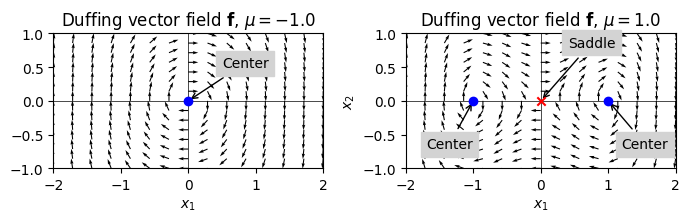

In [4]:
# Example: mu=1 => mu>0 => (three equilibria)
mu = 1.0

fig, (ax_pos, ax_neg) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, 5))
plot_field(ax=ax_neg, mu=mu, x1lim=(-2,2), x2lim=(-1,1))

ax_neg.annotate('Saddle', xy=(0, 0), xytext=(0.4, 0.8), arrowprops=dict(facecolor='black', arrowstyle='->'), backgroundcolor='lightgray', fontsize=10)
ax_neg.scatter([0], [0], color='red', marker="x", zorder=10)  # saddle point at origin
ax_neg.annotate('Center', xy=(mu**0.5, 0), xytext=(1.2, -0.7), arrowprops=dict(facecolor='black', arrowstyle='->'), backgroundcolor='lightgray', fontsize=10)
ax_neg.scatter([mu**0.5], [0], color='blue', zorder=10)  # center at (sqrt(mu), 0)
ax_neg.annotate('Center', xy=(-mu**0.5, 0), xytext=(-1.7, -0.7), arrowprops=dict(facecolor='black', arrowstyle='->'), backgroundcolor='lightgray', fontsize=10)
ax_neg.scatter([-mu**0.5], [0], color='blue', zorder=10)  # center at (-sqrt(mu), 0)

# Positive
plot_field(ax_pos, mu=-1.0, x1lim=(-2,2), x2lim=(-1,1))

ax_pos.annotate('Center', xy=(0, 0), xytext=(0.5, 0.5), arrowprops=dict(facecolor='black', arrowstyle='->'), backgroundcolor='lightgray', fontsize=10)
ax_pos.scatter([0], [0], color='blue', zorder=10)  # saddle point at origin
ax_pos.set_ylabel(None)

fig.tight_layout()
fig.savefig(IMG_DIR / '1_c_numerical.png', dpi=EXPORT_DPI, bbox_inches='tight')


### Problem 1e

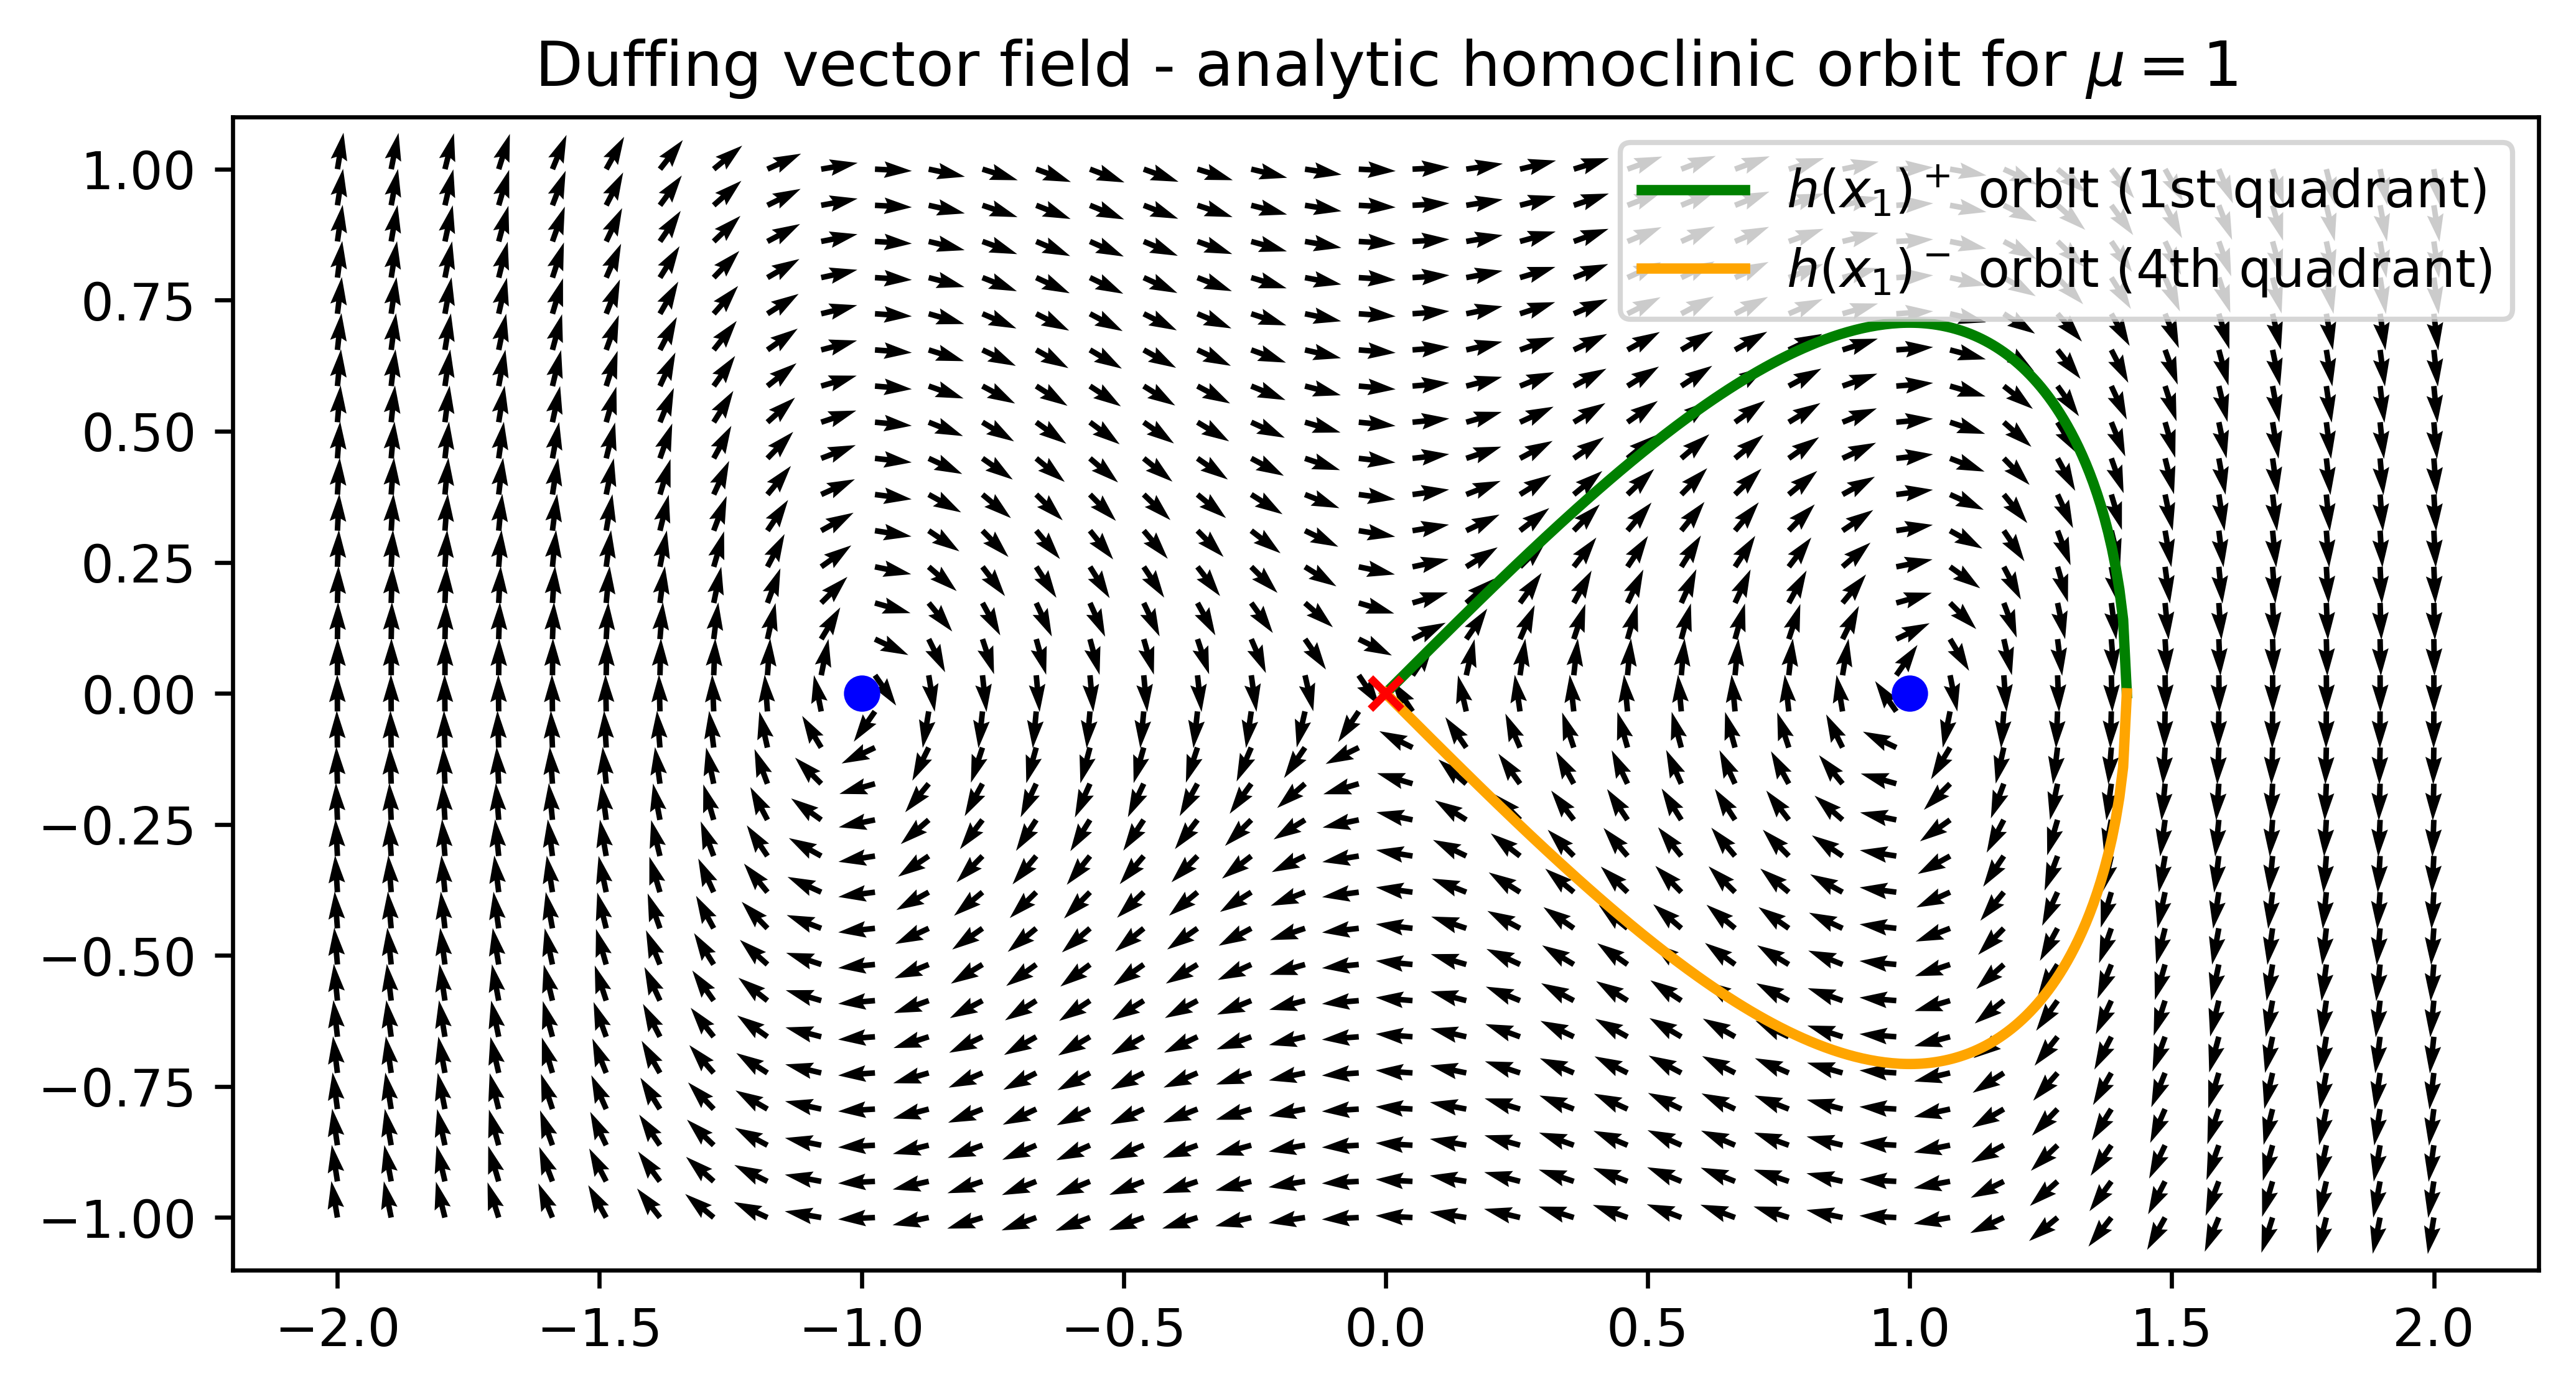

In [5]:
mu = 1.0
x1_vals = np.linspace(0, np.sqrt(2*mu), 200)
h_vals = x1_vals * np.sqrt(np.maximum(0, mu - 0.5*x1_vals**2))

# vector field (small region)
x1 = np.linspace(-2, 2, 40)
x2 = np.linspace(-1, 1, 30)
X1, X2 = np.meshgrid(x1, x2)
U = X2
V = mu*X1 - X1**3
N = np.sqrt(U**2 + V**2)

# plotting
plt.figure(figsize=(PAPER_WIDTH_IN,4), dpi=EXPORT_DPI)

plt.quiver(X1, X2, U/N, V/N, angles='xy')
plt.plot(x1_vals, h_vals, 'green', linewidth=2, label='$h(x_1)^+$ orbit (1st quadrant)')
plt.plot(x1_vals, -h_vals, 'orange', linewidth=2, label='$h(x_1)^-$ orbit (4th quadrant)')

#plt.scatter([0, np.sqrt(mu), -np.sqrt(mu)],[0,0,0], color='k')
plt.scatter([0], [0], color='red', marker="x", zorder=10)  # saddle point at origin
plt.scatter([mu**0.5], [0], color='blue')  # center at (sqrt(mu), 0)
plt.scatter([-mu**0.5], [0], color='blue')  # center at (-sqrt(mu), 0)

plt.gca().set_aspect('equal', 'box')
plt.legend(); plt.title('Duffing vector field - analytic homoclinic orbit for $μ=1$')

plt.tight_layout()
plt.savefig(IMG_DIR / '1_e.png', dpi=EXPORT_DPI, bbox_inches='tight')

# Problemo 2

### Problem 2a

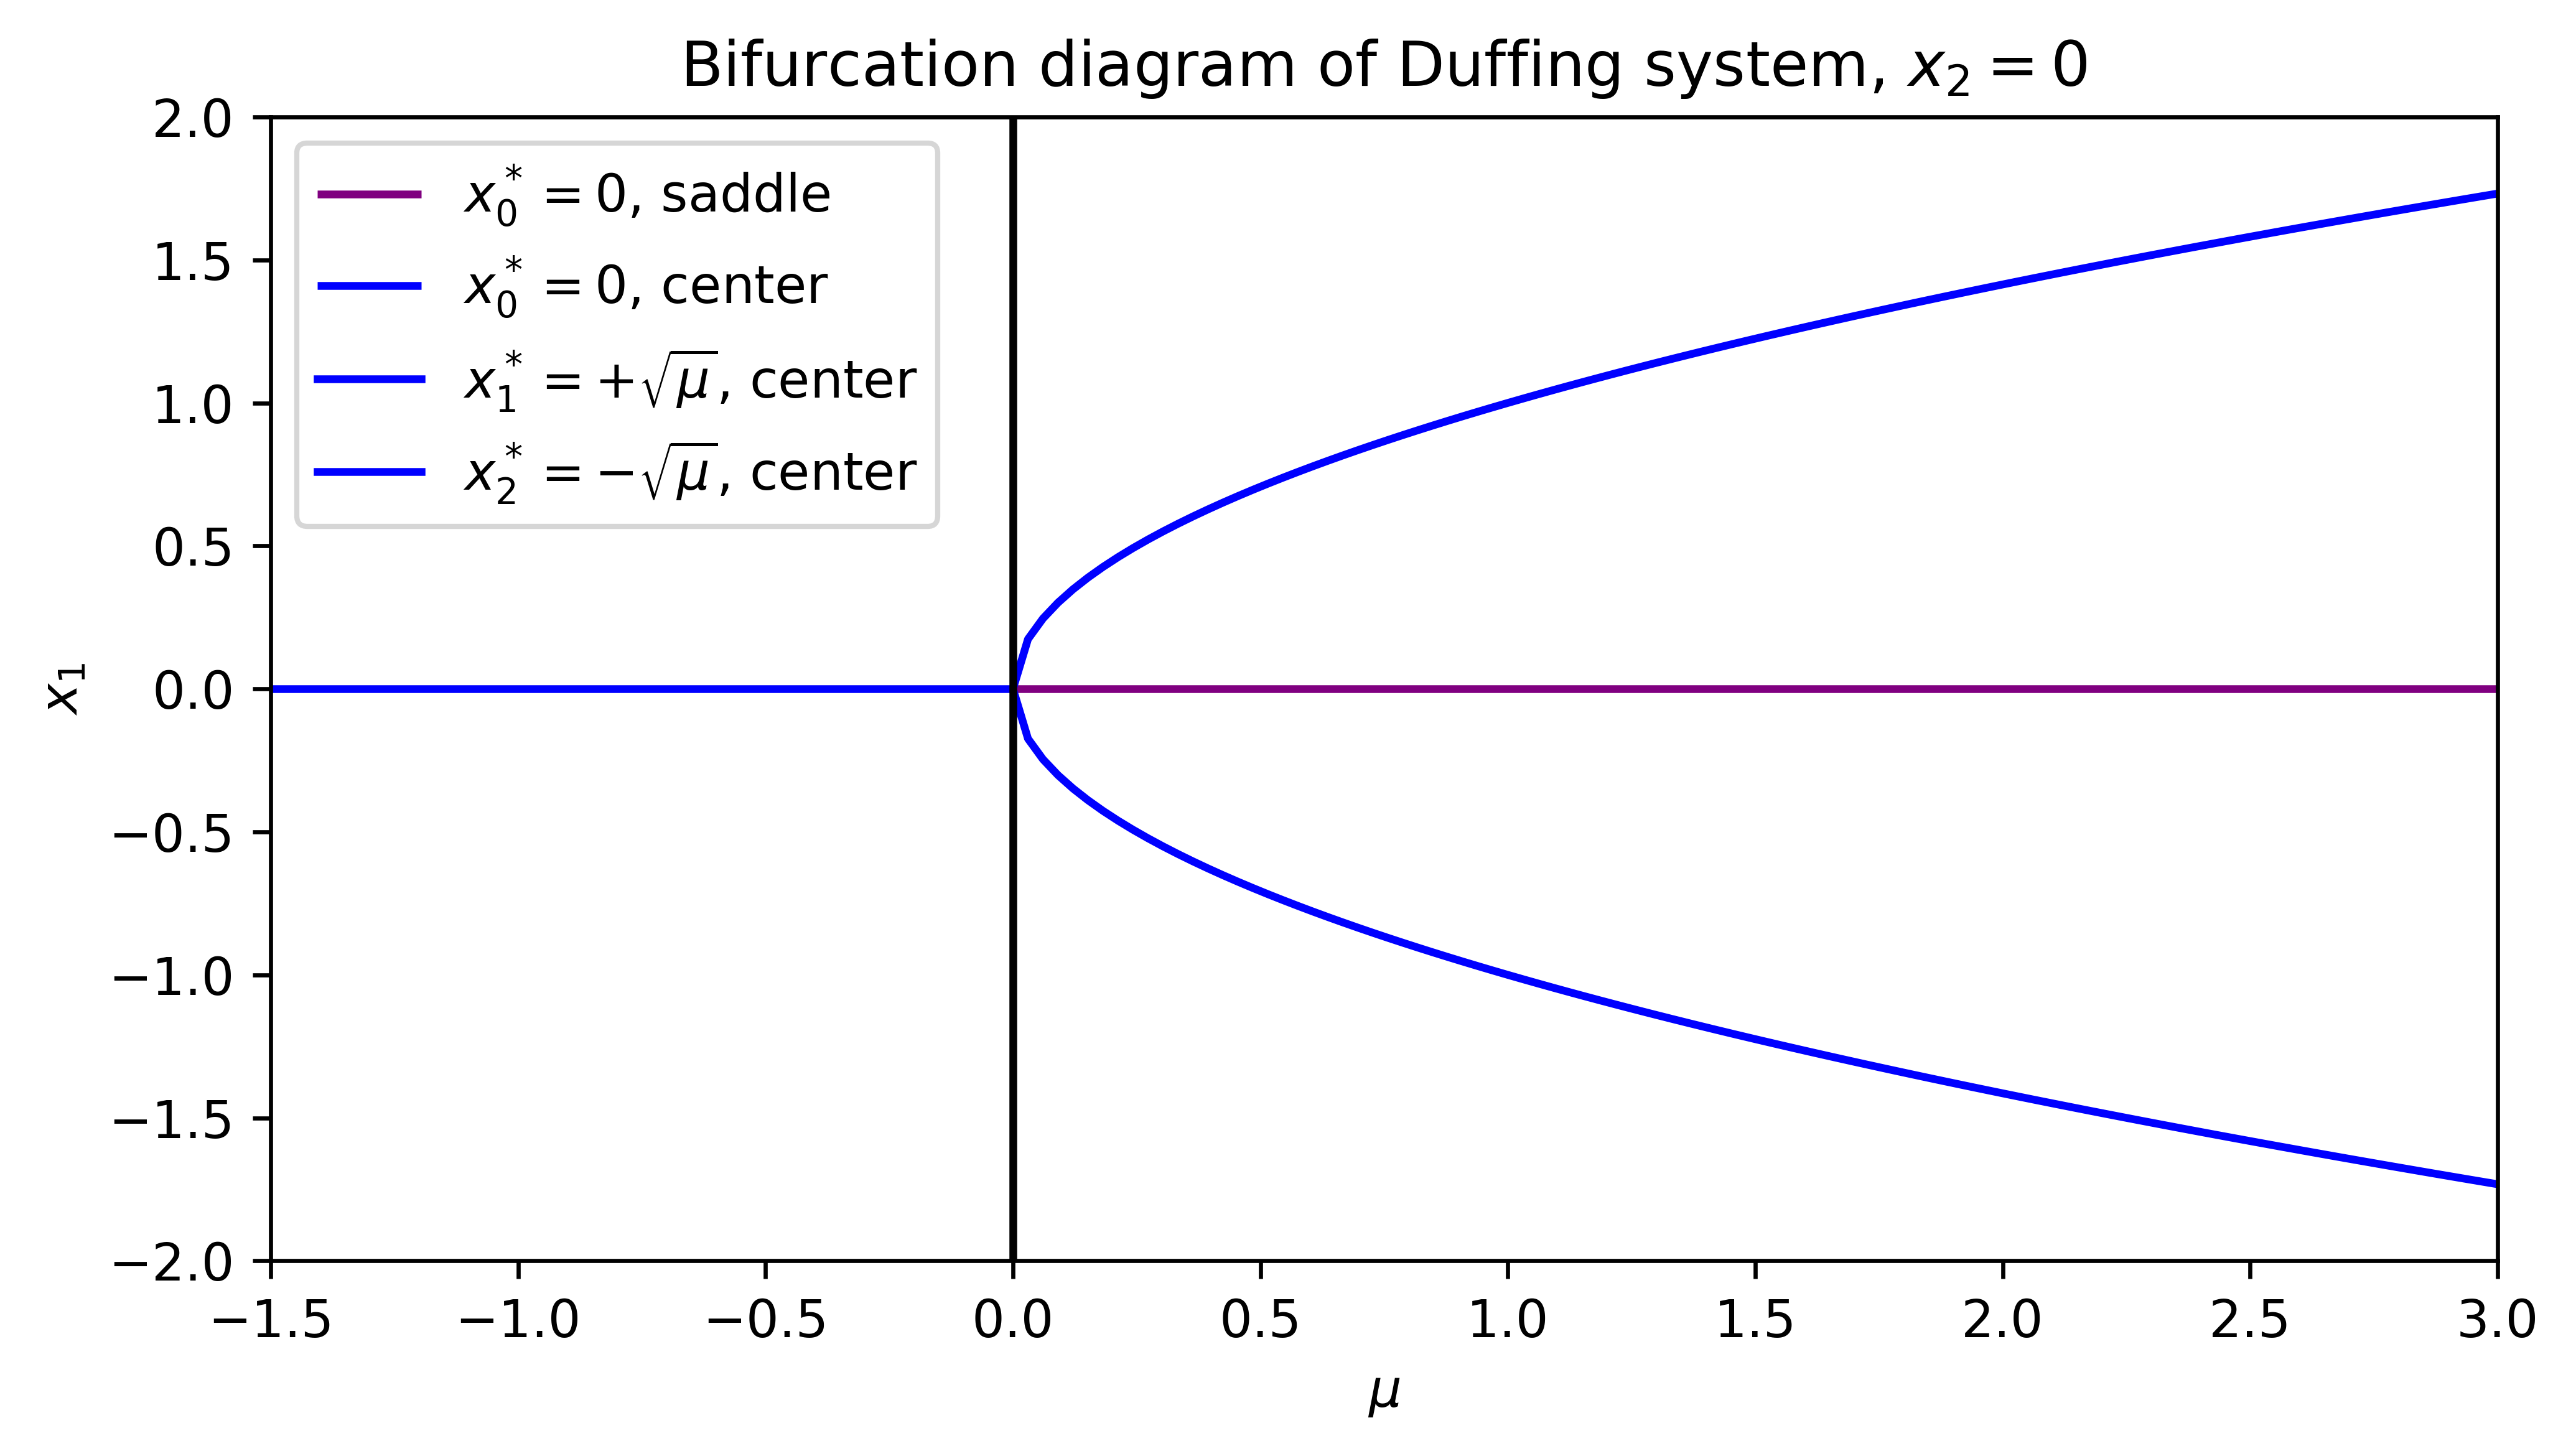

In [24]:
mu_xx = np.linspace(0, 3, 100)

plt.figure(figsize=(PAPER_WIDTH_IN,4), dpi=EXPORT_DPI)
plt.title("Bifurcation diagram of Duffing system, $x_2=0$")

# plt.scatter([0], [0], color='red')  # saddle point at origin
#plt.scatter([0], [mu**0.5], color='blue')  # center at (sqrt(mu), 0)
#plt.scatter([0], [-mu**0.5], color='blue')  # center at (-sqrt(mu), 0)

plt.hlines(0, 0, 3, colors='purple', linestyles='-', label='$x_0^*=0$, saddle')
#plt.hlines(mu**0.5, 0, 3, colors='blue', linestyles='--', label='$x^*_{1,2}= \pm \sqrt{\mu}$ center')
#plt.hlines(-mu**0.5, 0, 3, colors='blue', linestyles='--')
#plt.hlines(0, -3, 3, colors='green', linestyles='-', label="$x_2=0$", alpha=0.5)  # vertical line at mu=0
#plt.vlines(0, -mu**0.5, mu**0.5, colors='blue', linestyles='--', alpha=0.5)

plt.hlines(0, -1.5, 0, colors='blue', linestyles='-', label=r'$x^*_{0}= 0$, center')
plt.plot(mu_xx, np.sqrt(mu_xx), color='blue', linestyle='-', label=r'$x^*_{1}= + \sqrt{\mu}$, center')
plt.plot(mu_xx, -np.sqrt(mu_xx), color='blue', linestyle='-', label=r'$x^*_{2}= - \sqrt{\mu}$, center')

plt.axvline(0, color="black")
plt.xlim(-1.5,3); plt.ylim(-2,2)
plt.xlabel("$μ$")
plt.ylabel("$x_1$")
plt.legend()

plt.tight_layout()
plt.savefig(IMG_DIR / '2_a_numerical.png', dpi=EXPORT_DPI, bbox_inches='tight')

### Problem 2e

<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
C:\Users\jeppe\AppData\Local\Temp\ipykernel_35676\2430247727.py:23: SyntaxWarning: invalid escape sequence '\m'
  plt.title('Phase Plot $x_1, x_2$ and Contours of $V(x1,x2)$ for $\mu=0$')


Text(0, 0.5, '$x_2$')

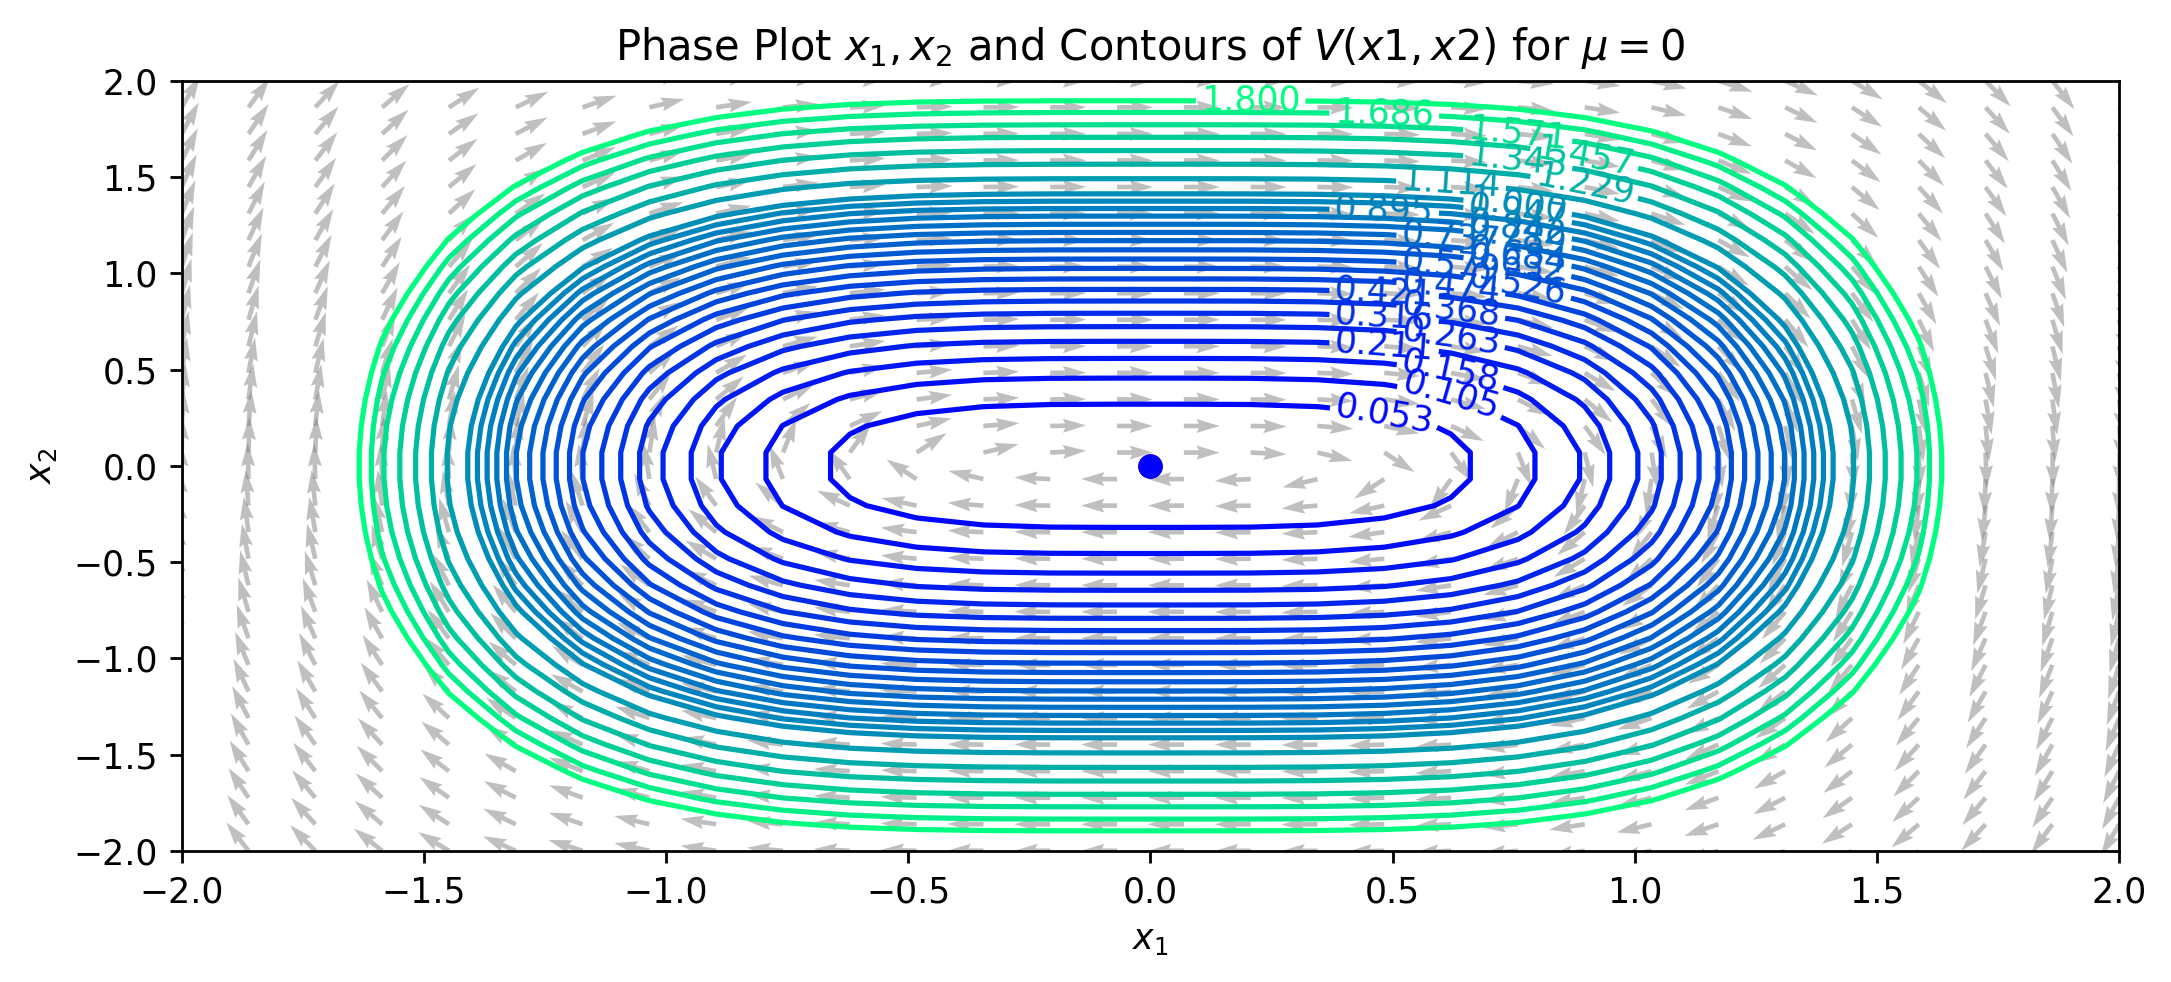

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Lyapunov function
def V(x1, x2):
    return 0.5*x2**2 + 0.25*x1**4

# Level Sets
x1 = np.linspace(-2,2,30)
x2 = np.linspace(-2,2,30)
X1, X2 = np.meshgrid(x1, x2)
Z = V(X1, X2)
levels = list(np.linspace(0, 1, 20)) + list(np.linspace(1, 1.8, 8))[1:]

# vector field (small region)
mu = 0.0
U = X2
V = mu*X1 - X1**3
N = np.sqrt(U**2 + V**2)

# plotting
plt.figure(figsize=(10,4), dpi=250)
plt.title('Phase Plot $x_1, x_2$ and Contours of $V(x1,x2)$ for $\mu=0$')

cs = plt.contour(X1, X2, Z, levels=levels, cmap='winter') #cmap "cool", "copper", "winter"
plt.clabel(cs)

plt.quiver(X1, X2, U/N, V/N, angles='xy', color="grey", alpha=0.5)
plt.scatter([0], [0], color='red')  # saddle point at origin
plt.scatter([mu**0.5], [0], color='blue')  # center at (sqrt(mu), 0)
plt.scatter([-mu**0.5], [0], color='blue')  # center at (-sqrt(mu), 0)

#plt.gca().set_aspect('equal', 'box')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')